# 02 · Statistical Evidence, Business Exposure & Decision Analysis

**Credit Card Fraud Analytics & Investigation Optimization**  
*Research notebook · inference, exposure, operational workload, and hypothetical economics*

> **Central research question:** Which patterns in this historical transaction dataset have statistical support, how do they translate into recorded fraud exposure, and why do apparently attractive segment-review rules become expensive under real investigation constraints?

**Evidence contract.** This notebook is **read-only** and uses the verified outputs of `src.statistical_analysis` and `src.business_analysis`. Statistical inference is exploratory, based on the **original duplicate-retained dataset**. No model training, test-set policy selection, causal claims, verified bank losses, invented currencies, or real intervention outcomes appear here.

**Three parts:** A · Statistical evidence and robustness | B · Business exposure and workload | C · Retrospective review rules and hypothetical economics.

**Boundary from other notebooks:** Notebook 01 describes the fraud landscape; Notebook 03 evaluates predictive models on locked holdouts; Notebook 04 compares *training-selected* ranking strategies under a fixed review budget. The five rules in this notebook are **in-sample descriptive segment screens**, not deployable classifiers.

## A · Statistical evidence
### 1. Research questions and source provenance

1. **RQ1:** Do fraud and legitimate transaction amounts differ, and how strong are those differences?
2. **RQ2:** Are amount segments associated with elevated observed fraud prevalence? What is the absolute and relative uncertainty?
3. **RQ3:** Which anonymized features exhibit class-conditional separation, without assigning them false business meanings?
4. **RQ4:** How sensitive are the value-concentration and risk findings to the rare fraud composition and duplicate decisions?
5. **RQ5:** What investigation workload and hypothetical economics follow from broad segment review rules?

**Caution:** Tests—including the PCA contrasts selected following prior EDA—are exploratory and not independent, preregistered confirmation. Holm adjustment accounts for the reported family of nine tests, not every analytic choice made during exploration.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 18)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
NAVY, TEAL, GOLD, RED, GREY = '#142c45', '#098c91', '#c58a37', '#cf505c', '#65758a'
plt.rcParams.update({'figure.dpi': 125, 'savefig.dpi': 140, 'font.size': 10, 'axes.titlesize': 12,
                    'axes.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                    'figure.facecolor': 'white', 'axes.facecolor': 'white'})

def find_root(path=None):
    start=(path or Path.cwd()).resolve()
    for root in (start, *start.parents):
        if (root/'reports/tables/statistics/hypothesis_tests.csv').is_file() and (root/'reports/tables/business/executive_kpis.csv').is_file():
            return root
    raise FileNotFoundError('Expected statistical and business reports not found. From the project root, run '
                            '`python -m src.statistical_analysis` and `python -m src.business_analysis`.')
ROOT=find_root()
STAT=ROOT/'reports/tables/statistics'
BIZ=ROOT/'reports/tables/business'

def read_report(folder, filename, required):
    path=folder/filename
    if not path.is_file(): raise FileNotFoundError(f'Missing report: {path.relative_to(ROOT)}')
    data=pd.read_csv(path)
    missing=set(required)-set(data.columns)
    if missing: raise ValueError(f'{filename}: required columns missing: {sorted(missing)}')
    if data.empty: raise ValueError(f'{filename} contains no rows')
    return data

def show(df, cols=None, formats=None, caption=None):
    if caption: display(Markdown(f'*{caption}*'))
    view=df[cols].copy() if cols is not None else df.copy()
    display(view.style.format(formats or {}, na_rep='—'))

def chart_finish(fig, ax=None):
    if ax is not None: ax.grid(axis='x' if ax.get_xlabel() and not ax.get_ylabel() else 'y', alpha=.15)
    fig.tight_layout()
    plt.show()

print('Report root:',ROOT)
print('Population: original transactions with exact duplicates retained; reports are not modified.')

Report root: E:\DataAnalytics\Projects\Credit_Card_Fraud_Analytics
Population: original transactions with exact duplicates retained; reports are not modified.


In [2]:
required = {
 'hypothesis_tests': (STAT,'hypothesis_tests.csv',{'test_id','feature','test','p_value','p_value_holm','effect_size','effect_size_name','reject_holm_at_0_05'}),
 'segment_risk': (STAT,'segment_risk.csv',{'comparison','n','fraud','fraud_rate_pct','fraud_rate_ci_low_pct','fraud_rate_ci_high_pct','reference_n','reference_fraud','reference_rate_pct','risk_ratio','risk_ratio_ci_low','risk_ratio_ci_high'}),
 'value_uncertainty': (STAT,'value_uncertainty.csv',{'metric','estimate_pct','ci_low_pct','ci_high_pct','bootstrap_resamples','method'}),
 'duplicate_sensitivity': (STAT,'duplicate_sensitivity.csv',{'dataset','transactions','fraud_cases','recorded_fraud_amount','highest_amount_decile_fraud_value_share_pct','zero_amount_fraud_rate_pct'}),
 'executive_kpis': (BIZ,'executive_kpis.csv',{'transactions','fraud_cases','legitimate_cases','fraud_rate_pct','total_recorded_value','recorded_fraud_value','fraud_value_share_pct'}),
 'amount_segment_exposure': (BIZ,'amount_segment_exposure.csv',{'amount_band','transactions','fraud_cases','fraud_amount','fraud_rate_pct','share_of_fraud_cases_pct','share_of_fraud_value_pct','fraud_value_per_1000_transactions','fraud_cases_per_1000_transactions','legitimate_cases'}),
 'time_segment_exposure': (BIZ,'time_segment_exposure.csv',{'time_segment','transactions','fraud_cases','fraud_amount','fraud_rate_pct','share_of_fraud_value_pct','elapsed_start_hours','elapsed_end_hours'}),
 'zero_amount_exposure': (BIZ,'zero_amount_exposure.csv',{'amount_type','transactions','fraud_cases','fraud_amount','fraud_rate_pct'}),
 'value_concentration': (BIZ,'value_concentration.csv',{'amount_band','fraud_cases','fraud_amount','share_of_fraud_value_pct','cumulative_fraud_value_pct'}),
 'review_policy_scenarios': (BIZ,'review_policy_scenarios.csv',{'policy','flagged_for_review','labeled_fraud_in_flagged','legitimate_in_flagged','observed_review_yield_pct','case_coverage_pct','flagged_fraud_value','value_coverage_pct','reviews_per_1000_transactions'}),
 'assumption_sensitivity': (BIZ,'assumption_sensitivity.csv',{'policy','assumed_cost_per_review','assumed_fraud_intervention_effectiveness','assumed_friction_cost_per_legitimate_review','flagged_for_review','gross_hypothetical_value_prevented','total_review_cost','total_false_positive_friction_cost','hypothetical_incremental_net_value'}),
}
reports={k:read_report(*v) for k,v in required.items()}
stat_meta=json.loads((STAT/'summary.json').read_text(encoding='utf-8'))
biz_meta=json.loads((BIZ/'methodology.json').read_text(encoding='utf-8'))
print('Loaded reports:',len(reports),'| statistical tests:',len(reports['hypothesis_tests']),
      '| retrospective rules:',len(reports['review_policy_scenarios']),
      '| hypothetical sensitivity rows:',len(reports['assumption_sensitivity']))
assert len(reports['hypothesis_tests'])==9
assert len(reports['review_policy_scenarios'])==5
assert len(reports['assumption_sensitivity'])==45
assert stat_meta['hypothesis_tests']==9 and stat_meta['analysis_type'].startswith('exploratory')
assert biz_meta['data_policy'].startswith('No rows altered')
print('PASS — required report families and methods verified')

Loaded reports: 11 | statistical tests: 9 | retrospective rules: 5 | hypothetical sensitivity rows: 45
PASS — required report families and methods verified


### 2. Source-of-truth reconciliations

We fail explicitly if the statistical report population, amount segmentation, zero-amount segmentation, review rules, or recorded fraudulent amounts disagree. This protects the notebook against accidentally mixing experiments, report generations or deduplicated data.

In [3]:
k=reports['executive_kpis'].iloc[0]
amount=reports['amount_segment_exposure'].sort_values('amount_band').reset_index(drop=True)
time=reports['time_segment_exposure'].sort_values('time_segment').reset_index(drop=True)
zero=reports['zero_amount_exposure']
policy=reports['review_policy_scenarios']
conc=reports['value_concentration'].sort_values('amount_band').reset_index(drop=True)
N, F, FV=int(k.transactions),int(k.fraud_cases),float(k.recorded_fraud_value)
assert N==284807 and F==492 and np.isclose(FV,60127.97,atol=.01),'Unexpected data version: inspect report provenance.'
assert int(k.legitimate_cases)==N-F
assert int(amount.transactions.sum())==N and int(amount.fraud_cases.sum())==F
assert np.isclose(amount.fraud_amount.sum(),FV,atol=.01)
assert int(time.transactions.sum())==N and int(time.fraud_cases.sum())==F
assert int(zero.transactions.sum())==N and int(zero.fraud_cases.sum())==F
assert np.isclose(zero.fraud_amount.sum(),FV,atol=.01)
assert np.isclose(conc.fraud_amount.sum(),FV,atol=.01)
assert np.isclose(conc.cumulative_fraud_value_pct.iloc[-1],100,atol=.02)
assert int(policy.loc[policy.policy.eq('review_all'),'flagged_for_review'].iloc[0])==N
assert int(policy.loc[policy.policy.eq('review_all'),'labeled_fraud_in_flagged'].iloc[0])==F
assert np.isclose(policy.loc[policy.policy.eq('review_all'),'flagged_fraud_value'].iloc[0],FV,atol=.01)
assert int(stat_meta['observations'])==N and int(stat_meta['fraud_cases'])==F
checks=pd.DataFrame({'Evidence':['Original transactions','Fraud labels','Recorded fraudulent value','Amount-band transactions','Time-band transactions','Zero/positive transactions','Policy review-all records'],
                     'Observed':[N,F,FV,int(amount.transactions.sum()),int(time.transactions.sum()),int(zero.transactions.sum()),int(policy.loc[policy.policy.eq('review_all'),'flagged_for_review'].iloc[0])],
                     'Status':['PASS']*7})
show(checks,formats={'Observed':'{:,.2f}'})
print('PASS — all cross-module reconciliations')

,Evidence,Observed,Status
0,Original transactions,"284,807.00",PASS
1,Fraud labels,492.00,PASS
2,Recorded fraudulent value,"60,127.97",PASS
3,Amount-band transactions,"284,807.00",PASS
4,Time-band transactions,"284,807.00",PASS
5,Zero/positive transactions,"284,807.00",PASS
6,Policy review-all records,"284,807.00",PASS


PASS — all cross-module reconciliations


### 3. Nine exploratory tests: statistical evidence is not practical significance

The report stores **raw and Holm-adjusted** p-values for one predeclared *reported test family*. It includes two tests of Amount, one decile association test, a Fisher comparison for zero amounts, and five PCA tests. The PCA features were highlighted in earlier EDA; correcting p-values does not undo this selection step. A small p-value does **not** imply a large effect, high precision, or policy usefulness.

In [4]:
tests=reports['hypothesis_tests'].copy()
tests['holm_significant']=tests['p_value_holm']<.05
assert tests['test_id'].nunique()==9 and tests.holm_significant.all()
assert np.all(tests.p_value_holm>=tests.p_value-1e-300)
show(tests,['feature','test','effect_size_name','effect_size','p_value','p_value_holm','holm_significant'],
     {'effect_size':'{:+.4f}','p_value':'{:.3e}','p_value_holm':'{:.3e}'},
     'Nine exploratory tests with original and family-wise adjusted p-values')
print('Holm-significant tests:',int(tests.holm_significant.sum()),'of',len(tests))

*Nine exploratory tests with original and family-wise adjusted p-values*

,feature,test,effect_size_name,effect_size,p_value,p_value_holm,holm_significant
0,Amount,Mann-Whitney U (two-sided),rank_biserial,-0.1159,8.578e-06,8.578e-06,True
1,Amount,"Two-sample KS (asymptotic, tied values)",KS_D,+0.2712,2.170e-32,6.511e-32,True
2,Amount deciles,Pearson chi-square independence,Cramers_V,+0.0392,1.929e-88,7.716e-88,True
3,Amount == 0,Fisher exact (two-sided),odds_ratio,+9.1236,6.259e-17,1.252e-16,True
4,V14,Mann-Whitney U (two-sided),rank_biserial,-0.8983,1.472e-260,1.324e-259,True
5,V17,Mann-Whitney U (two-sided),rank_biserial,-0.6164,9.219e-124,4.610e-123,True
6,V12,Mann-Whitney U (two-sided),rank_biserial,-0.8741,8.416e-247,6.733e-246,True
7,V10,Mann-Whitney U (two-sided),rank_biserial,-0.8281,9.611e-222,6.728e-221,True
8,V7,Mann-Whitney U (two-sided),rank_biserial,-0.6716,1.464e-146,8.785e-146,True


Holm-significant tests: 9 of 9


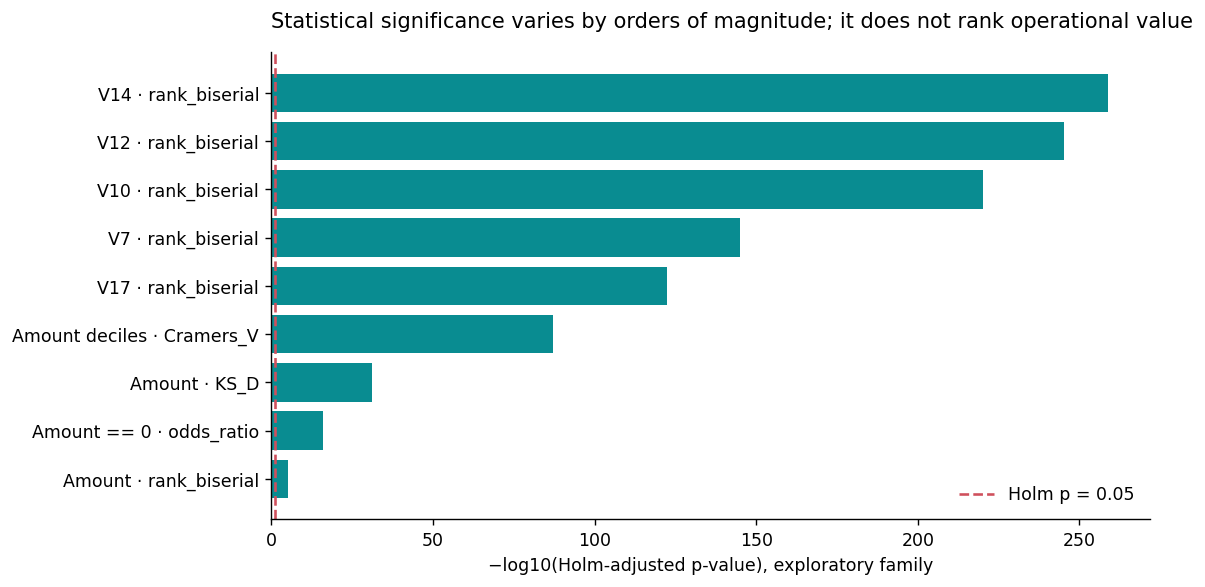

In [5]:
fig,ax=plt.subplots(figsize=(9.4,4.8))
rank=tests.sort_values('p_value_holm',ascending=False).copy()
x=-np.log10(rank.p_value_holm.clip(lower=1e-300))
ax.barh(rank.feature+' · '+rank.effect_size_name,x,color=[TEAL if p<.05 else GREY for p in rank.p_value_holm])
ax.axvline(-np.log10(.05),color=RED,linestyle='--',label='Holm p = 0.05')
ax.set_xlabel('−log10(Holm-adjusted p-value), exploratory family')
ax.set_title('Statistical significance varies by orders of magnitude; it does not rank operational value',loc='left',pad=14)
ax.legend(frameon=False,loc='lower right')
chart_finish(fig)

**Interpretation.** All nine reported comparisons pass the Holm-adjusted 0.05 threshold, which is unsurprising for some contrasts in a very large dataset. Their effect sizes tell a different story. In particular, the amount-decile Cramér's V is small despite its extremely low adjusted p-value; this is **not** a strong fraud-screening rule. Tests with ties (especially the two-sample asymptotic KS result) carry the limitations documented by the source report. Odds ratio, risk ratio, KS distance, rank-biserial correlation and Cramér's V have different definitions and cannot be pooled into one arbitrary "strength" score.

### 4. Amount differences: distinguish distributional tests from classification utility

Two complementary tests address different aspects of `Amount`: Mann–Whitney U summarizes a rank-based ordering contrast; KS summarizes the maximum observed distributional separation. Both tests compare the *historical* fraud and legitimate populations, without providing a deployable alert threshold.

In [6]:
amt_tests=tests.loc[tests.test_id.isin(['amount_mann_whitney','amount_ks','amount_decile_chi_square'])]
show(amt_tests,['test','statistic','effect_size_name','effect_size','p_value_holm','interpretation'],
     {'statistic':'{:,.4g}','effect_size':'{:+.4f}','p_value_holm':'{:.3e}'})
print('Amount alone: statistically different distributions ≠ reliable fraud classifier.')

,test,statistic,effect_size_name,effect_size,p_value_holm,interpretation
0,Mann-Whitney U (two-sided),6.183e+07,rank_biserial,-0.1159,8.578e-06,"Rank-based separation, not a test of mean difference"
1,"Two-sample KS (asymptotic, tied values)",0.2712,KS_D,+0.2712,6.511e-32,Distribution-shape comparison; ties make p approximate
2,Pearson chi-square independence,436.8,Cramers_V,+0.0392,7.716e-88,df=9; minimum expected cell=45.7


Amount alone: statistically different distributions ≠ reliable fraud classifier.


### 5. Zero-value versus positive-value records: absolute risk, relative risk and uncertainty

Use the report's **Wilson intervals for individual fraud rates** and its **approximate confidence interval for the relative risk**. The Fisher test in the hypothesis table produces an **odds ratio**, not the reported risk ratio. The existence of zero-amount records does not reveal their purpose.

In [7]:
risk=reports['segment_risk']
rr=risk.loc[risk.comparison.eq('zero_vs_positive')].iloc[0]
assert int(rr.n)==int(zero.loc[zero.amount_type.eq('zero'),'transactions'].iloc[0])
assert int(rr.fraud)==int(zero.loc[zero.amount_type.eq('zero'),'fraud_cases'].iloc[0])
assert int(rr.reference_n)+int(rr.n)==N and int(rr.reference_fraud)+int(rr.fraud)==F
risk_view=pd.DataFrame({'Group':[rr['group'],rr.reference_group],
                        'Transactions':[int(rr.n),int(rr.reference_n)],
                        'Fraud cases':[int(rr.fraud),int(rr.reference_fraud)],
                        'Fraud rate (%)':[rr.fraud_rate_pct,rr.reference_rate_pct],
                        'Wilson lower (%)':[rr.fraud_rate_ci_low_pct,rr.reference_rate_ci_low_pct],
                        'Wilson upper (%)':[rr.fraud_rate_ci_high_pct,rr.reference_rate_ci_high_pct]})
show(risk_view,formats={'Transactions':'{:,.0f}','Fraud cases':'{:,.0f}',
     'Fraud rate (%)':'{:.4f}','Wilson lower (%)':'{:.4f}','Wilson upper (%)':'{:.4f}'})
print(f'Observed risk ratio: {rr.risk_ratio:.2f} (approx. 95% CI: {rr.risk_ratio_ci_low:.2f}–{rr.risk_ratio_ci_high:.2f})')
print(f'Absolute rate difference: {rr.difference_percentage_points:+.3f} percentage points')

,Group,Transactions,Fraud cases,Fraud rate (%),Wilson lower (%),Wilson upper (%)
0,Zero amount,"1,825",27,1.4795,1.0187,2.1440
1,Positive amount,"282,982",465,0.1643,0.1501,0.1799


Observed risk ratio: 9.00 (approx. 95% CI: 6.12–13.23)
Absolute rate difference: +1.315 percentage points


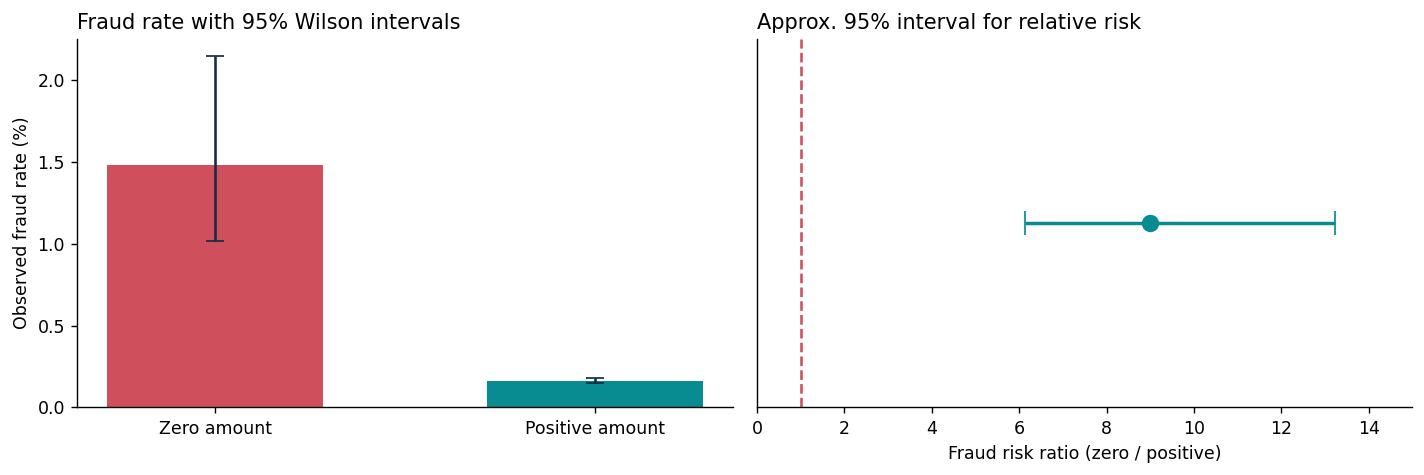

In [8]:
fig,axs=plt.subplots(1,2,figsize=(11.5,3.9))
rate=risk_view['Fraud rate (%)'].to_numpy()
low=rate-risk_view['Wilson lower (%)'].to_numpy()
high=risk_view['Wilson upper (%)'].to_numpy()-rate
axs[0].bar([0,1],rate,color=[RED,TEAL],width=.57)
axs[0].errorbar([0,1],rate,yerr=[low,high],fmt='none',ecolor=NAVY,capsize=5,lw=1.5)
axs[0].set_xticks([0,1],['Zero amount','Positive amount']);axs[0].set_ylabel('Observed fraud rate (%)')
axs[0].set_title('Fraud rate with 95% Wilson intervals',loc='left')
axs[1].errorbar(rr.risk_ratio,0,xerr=[[rr.risk_ratio-rr.risk_ratio_ci_low],[rr.risk_ratio_ci_high-rr.risk_ratio]],
                fmt='o',color=TEAL,capsize=7,markersize=9,lw=2)
axs[1].axvline(1,color=RED,ls='--');axs[1].set_xlim(0,max(15,rr.risk_ratio_ci_high*1.13));axs[1].set_ylim(-.8,.8)
axs[1].set_yticks([]);axs[1].set_xlabel('Fraud risk ratio (zero / positive)')
axs[1].set_title('Approx. 95% interval for relative risk',loc='left')
fig.tight_layout();plt.show()

**Decision interpretation.** Zero-amount records have a much higher *observed* fraud rate, yet **zero recorded transaction value**. This could warrant contextual investigation, but its cause and operational meaning are unknown; it is not evidence for automatically blocking such transactions. The 1.48% rate is still low in absolute terms. Compare the low baseline fraud probability, interval widths and the cost of reviewing 1,825 transactions.

### 6. Anonymized components: separation without invented semantics

The five selected PCA components were chosen following earlier exploratory analysis. Their **rank-biserial effect sizes** are comparable *within this measure*; the negative sign depends on the class ordering used in the pipeline and does not imply a business interpretation for a component.

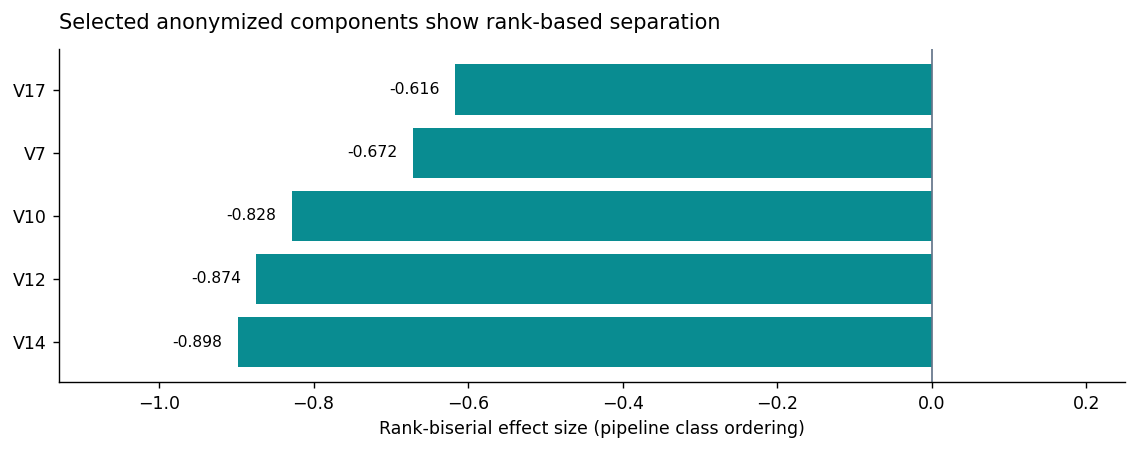

,feature,effect_size,p_value_holm
4,V14,-0.8983,1.324e-259
6,V12,-0.8741,6.733e-246
7,V10,-0.8281,6.728e-221
8,V7,-0.6716,8.785e-146
5,V17,-0.6164,4.610e-123


In [9]:
pca=tests.loc[tests.feature.str.fullmatch(r'V\d+'),:].copy().sort_values('effect_size')
fig,ax=plt.subplots(figsize=(9.2,3.7))
ax.barh(pca.feature,pca.effect_size,color=TEAL)
for i,v in enumerate(pca.effect_size): ax.text(v+.02 if v>=0 else v-.02,i,f'{v:+.3f}',va='center',ha='left' if v>=0 else 'right',fontsize=9)
ax.axvline(0,color=GREY,lw=1);ax.set_xlim(-1.13,.25)
ax.set_xlabel('Rank-biserial effect size (pipeline class ordering)')
ax.set_title('Selected anonymized components show rank-based separation',loc='left',pad=12)
fig.tight_layout();plt.show()
show(pca,['feature','effect_size','p_value_holm'],{'effect_size':'{:+.4f}','p_value_holm':'{:.3e}'})

**Boundary.** Strong class-conditional separation can motivate modeling, but it does not establish calibrated fraud probabilities, independence between components, interpretable merchant/customer risk factors, or generalization to future transactions. Notebook 03 addresses out-of-sample model evaluation.

### 7. Bootstrap uncertainty and duplicate sensitivity

The reported bootstrap samples **fraud-labeled rows 2,000 times**, uses a **percentile interval**, and holds the *original amount-decile boundaries fixed*. Its interval is conditional on the fraud-record composition and does **not** account for cardholder dependence, future drift or uncertainty about bank losses. Duplicate removal is a different sensitivity analysis.

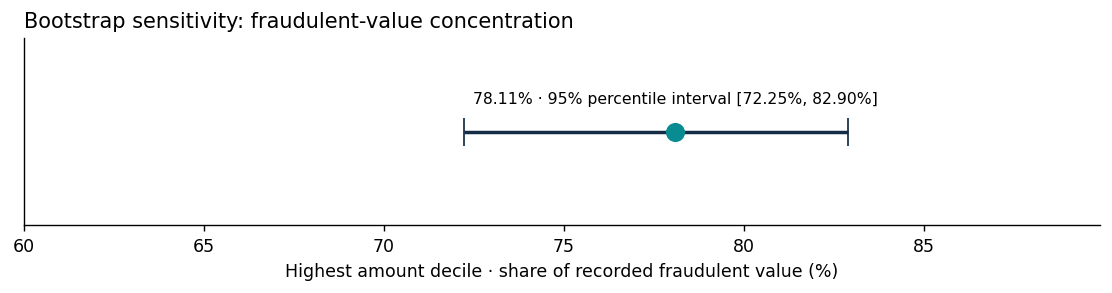

2,000 bootstrap replicates | seed 42 | Fraud-row iid percentile bootstrap; full-data decile boundaries fixed


In [10]:
unc=reports['value_uncertainty'].iloc[0]
assert int(unc.bootstrap_resamples)==int(stat_meta['bootstrap_resamples'])
assert np.isclose(unc.estimate_pct,amount.share_of_fraud_value_pct.iloc[-1],atol=.01)
fig,ax=plt.subplots(figsize=(9,2.45))
ax.errorbar(unc.estimate_pct,0,xerr=[[unc.estimate_pct-unc.ci_low_pct],[unc.ci_high_pct-unc.estimate_pct]],
            fmt='o',color=TEAL,ecolor=NAVY,capsize=8,markersize=10,lw=2)
ax.set_xlim(min(60,unc.ci_low_pct-5),min(100,unc.ci_high_pct+7));ax.set_ylim(-.6,.6);ax.set_yticks([])
ax.set_xlabel('Highest amount decile · share of recorded fraudulent value (%)')
ax.set_title('Bootstrap sensitivity: fraudulent-value concentration',loc='left')
ax.text(unc.estimate_pct,.18,f'{unc.estimate_pct:.2f}% · 95% percentile interval [{unc.ci_low_pct:.2f}%, {unc.ci_high_pct:.2f}%]',ha='center',fontsize=9)
fig.tight_layout();plt.show()
print(f'{int(unc.bootstrap_resamples):,} bootstrap replicates | seed {int(unc.seed)} | {unc.method}')

In [11]:
dup=reports['duplicate_sensitivity'].copy()
assert len(dup)==2
orig=dup.loc[dup.dataset.eq('original_keep_duplicates')].iloc[0]
dedup=dup.loc[dup.dataset.eq('exact_duplicates_removed')].iloc[0]
assert int(orig.transactions)==N and int(orig.fraud_cases)==F
assert int(orig.transactions)-int(dedup.transactions)==int(k.duplicate_rows)
sens=dup[['dataset','transactions','fraud_cases','fraud_rate_pct','recorded_fraud_amount',
          'highest_amount_decile_fraud_value_share_pct','zero_amount_fraud_rate_pct']]
show(sens,formats={'transactions':'{:,.0f}','fraud_cases':'{:,.0f}', 'fraud_rate_pct':'{:.4f}',
    'recorded_fraud_amount':'{:,.2f}', 'highest_amount_decile_fraud_value_share_pct':'{:.2f}',
    'zero_amount_fraud_rate_pct':'{:.3f}'})
print(f'Duplicates removed: {int(orig.transactions-dedup.transactions):,} rows; '
      f'{int(orig.fraud_cases-dedup.fraud_cases)} fraud labels; '
      f'{orig.recorded_fraud_amount-dedup.recorded_fraud_amount:,.2f} recorded fraud amount units')

,dataset,transactions,fraud_cases,fraud_rate_pct,recorded_fraud_amount,highest_amount_decile_fraud_value_share_pct,zero_amount_fraud_rate_pct
0,original_keep_duplicates,"284,807",492,0.1727,"60,127.97",78.11,1.479
1,exact_duplicates_removed,"283,726",473,0.1667,"58,591.39",78.31,1.383


Duplicates removed: 1,081 rows; 19 fraud labels; 1,536.58 recorded fraud amount units


**Robustness interpretation.** Exact deduplication removes 1,081 rows, including 19 fraud labels; the highest-decile fraudulent-value share shifts modestly, but zero-amount fraud prevalence also changes. Therefore, duplicate policy should remain explicit. The bootstrap and duplicate sensitivity describe *different uncertainty mechanisms* and must not be combined into a single confidence interval.

## B · Business exposure and operational relevance
### 8. Executive exposure: observed counts are not realized losses

Recorded fraud value is `sum(Amount where Class == 1)`. It is **not** a verified chargeback, reimbursed loss, confirmed preventable amount or expected economic benefit. Amount units lack verified currency. This section translates descriptive evidence into exposure measures without changing those definitions.

In [12]:
exposure=pd.DataFrame([
 ('Observed transactions',f'{N:,}','Original, duplicates retained'),
 ('Labeled fraud transactions',f'{F:,}','Class = 1'),
 ('Observed fraud prevalence',f'{k.fraud_rate_pct:.4f}%','Fraud labels / transactions'),
 ('Recorded total transaction amount',f'{k.total_recorded_value:,.2f}','Unverified amount units'),
 ('Recorded fraudulent transaction amount',f'{FV:,.2f}','Not confirmed bank loss'),
 ('Fraud-labeled share of recorded amount',f'{k.fraud_value_share_pct:.3f}%','Fraud amount / all recorded amount'),
 ('Mean fraud transaction amount',f'{k.mean_fraud_amount:,.2f}','Sensitive to large values'),
 ('Median fraud transaction amount',f'{k.median_fraud_amount:,.2f}','Typical amount less skew-sensitive')],
 columns=['Business measure','Observed result','Interpretation'])
show(exposure)
assert np.isclose(FV/float(k.total_recorded_value)*100,float(k.fraud_value_share_pct),atol=.001)

,Business measure,Observed result,Interpretation
0,Observed transactions,"284,807","Original, duplicates retained"
1,Labeled fraud transactions,492,Class = 1
2,Observed fraud prevalence,0.1727%,Fraud labels / transactions
3,Recorded total transaction amount,"25,162,590.01",Unverified amount units
4,Recorded fraudulent transaction amount,"60,127.97",Not confirmed bank loss
5,Fraud-labeled share of recorded amount,0.239%,Fraud amount / all recorded amount
6,Mean fraud transaction amount,122.21,Sensitive to large values
7,Median fraud transaction amount,9.25,Typical amount less skew-sensitive


### 9. Amount-band exposure: prevalence, frequency, value and review burden

The ten bands come from the original business report. Each band has four distinct quantities: (i) transactions exposed to review, (ii) observed fraud rate, (iii) number of fraud labels, and (iv) recorded fraudulent amount. We preserve the original quantile segmentation instead of redefining it in this notebook.

In [13]:
amount['band_label']='Q'+(amount.amount_band.astype(int)+1).astype(str).str.zfill(2)
amount['legitimate_checks_per_fraud']=amount.legitimate_cases/amount.fraud_cases.replace(0,np.nan)
show(amount,['band_label','transactions','fraud_cases','legitimate_cases','fraud_rate_pct',
             'share_of_fraud_cases_pct','share_of_fraud_value_pct','fraud_value_per_1000_transactions'],
 {'transactions':'{:,.0f}','fraud_cases':'{:,.0f}','legitimate_cases':'{:,.0f}',
  'fraud_rate_pct':'{:.3f}','share_of_fraud_cases_pct':'{:.2f}',
  'share_of_fraud_value_pct':'{:.2f}','fraud_value_per_1000_transactions':'{:,.2f}'})

,band_label,transactions,fraud_cases,legitimate_cases,fraud_rate_pct,share_of_fraud_cases_pct,share_of_fraud_value_pct,fraud_value_per_1000_transactions
0,Q01,"30,492",181,"30,311",0.594,36.79,0.23,4.58
1,Q02,"26,473",27,"26,446",0.102,5.49,0.09,1.93
2,Q03,"28,559",36,"28,523",0.126,7.32,0.37,7.73
3,Q04,"28,405",13,"28,392",0.046,2.64,0.23,4.94
4,Q05,"28,714",14,"28,700",0.049,2.85,0.43,8.94
5,Q06,"28,375",17,"28,358",0.060,3.46,0.83,17.54
6,Q07,"28,366",24,"28,342",0.085,4.88,1.83,38.86
7,Q08,"28,915",50,"28,865",0.173,10.16,7.67,159.46
8,Q09,"28,050",45,"28,005",0.160,9.15,10.22,219.00
9,Q10,"28,458",85,"28,373",0.299,17.28,78.11,"1,650.36"


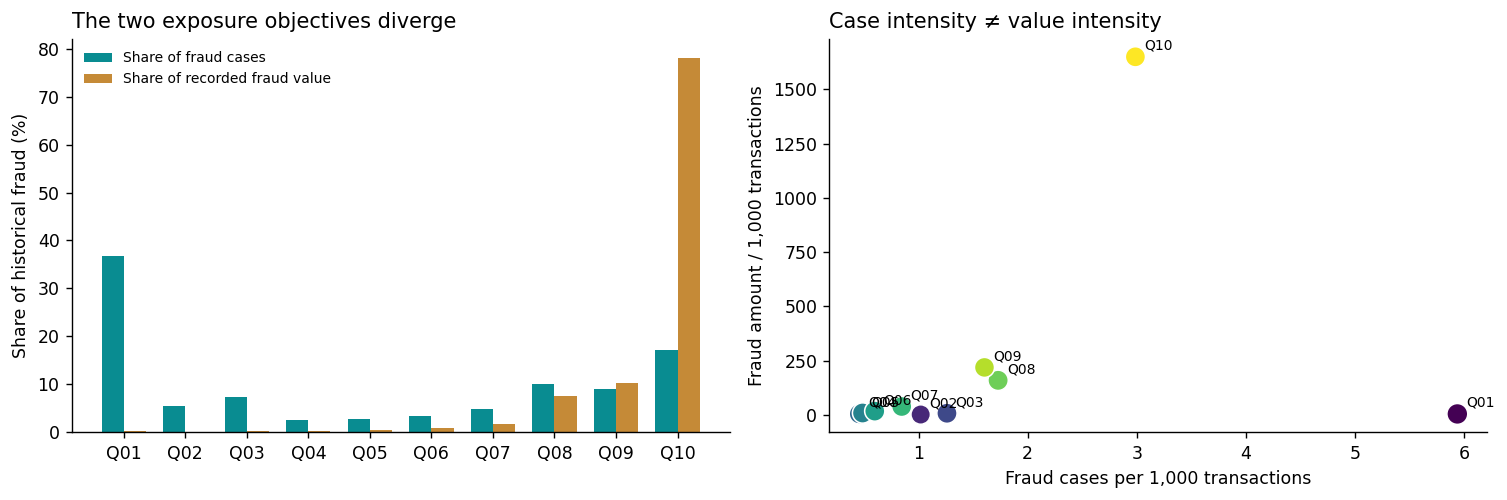

In [14]:
fig,axs=plt.subplots(1,2,figsize=(12.2,4.1))
xx=np.arange(len(amount))
axs[0].bar(xx-.18,amount.share_of_fraud_cases_pct,width=.36,color=TEAL,label='Share of fraud cases')
axs[0].bar(xx+.18,amount.share_of_fraud_value_pct,width=.36,color=GOLD,label='Share of recorded fraud value')
axs[0].set_xticks(xx,amount.band_label);axs[0].set_ylabel('Share of historical fraud (%)')
axs[0].set_title('The two exposure objectives diverge',loc='left');axs[0].legend(frameon=False,fontsize=8)
axs[1].scatter(amount.fraud_cases_per_1000_transactions,amount.fraud_value_per_1000_transactions,
               s=amount.transactions/210,c=np.arange(len(amount)),cmap='viridis',edgecolor='white',linewidth=.9)
for _,row in amount.iterrows():
 axs[1].annotate(row.band_label,(row.fraud_cases_per_1000_transactions,row.fraud_value_per_1000_transactions),xytext=(5,4),textcoords='offset points',fontsize=8)
axs[1].set_xlabel('Fraud cases per 1,000 transactions');axs[1].set_ylabel('Fraud amount / 1,000 transactions')
axs[1].set_title('Case intensity ≠ value intensity',loc='left')
fig.tight_layout();plt.show()

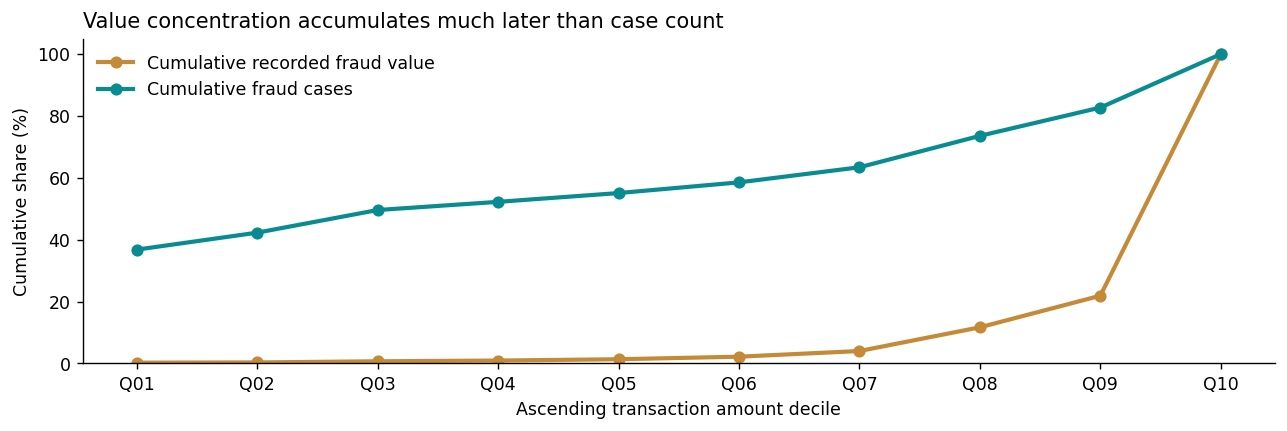

In [15]:
assert len(conc)==len(amount)
assert np.allclose(conc.share_of_fraud_value_pct,amount.share_of_fraud_value_pct,atol=1e-6)
fig,ax=plt.subplots(figsize=(10.4,3.55))
ax.plot(amount.band_label,conc.cumulative_fraud_value_pct,color=GOLD,marker='o',lw=2.4,label='Cumulative recorded fraud value')
ax.plot(amount.band_label,amount.share_of_fraud_cases_pct.cumsum(),color=TEAL,marker='o',lw=2.4,label='Cumulative fraud cases')
ax.set_ylim(0,105);ax.set_ylabel('Cumulative share (%)');ax.set_xlabel('Ascending transaction amount decile')
ax.set_title('Value concentration accumulates much later than case count',loc='left')
ax.legend(frameon=False);chart_finish(fig)

**Business interpretation.** The highest amount decile holds approximately **78.11% of recorded fraudulent value**, but only **17.28% of fraud labels**. The lowest decile holds roughly **36.79% of fraud labels** but **0.23% of value**. That suggests evaluating both case and value objectives. However, the whole highest decile also contains **28,373 legitimate transactions**, so a blanket screening rule can be operationally inefficient. These are in-sample descriptions, not prospective policy effectiveness estimates.

### 10. Elapsed-time exposure: risk is not workload

Observed fraud prevalence varies across four-hour **elapsed-time segments**, not verified local clock hours. Compare rates alongside segment volume and value intensity, without claiming daily periodicity or a predictable peak shift.

In [16]:
time['window']=time.apply(lambda r:f'{r.elapsed_start_hours:.0f}–{r.elapsed_end_hours:.0f}h',axis=1)
show(time,['window','transactions','fraud_cases','fraud_rate_pct','fraud_amount','fraud_value_per_1000_transactions'],
     {'transactions':'{:,.0f}','fraud_cases':'{:,.0f}','fraud_rate_pct':'{:.3f}',
      'fraud_amount':'{:,.2f}','fraud_value_per_1000_transactions':'{:,.2f}'})

,window,transactions,fraud_cases,fraud_rate_pct,fraud_amount,fraud_value_per_1000_transactions
0,0–4h,"9,577",38,0.397,"2,877.76",300.49
1,4–8h,"7,962",43,0.540,"5,068.82",636.63
2,8–12h,"29,862",65,0.218,"6,765.78",226.57
3,12–16h,"31,182",45,0.144,"3,459.81",110.96
4,16–20h,"32,269",48,0.149,"10,430.77",323.24
5,20–24h,"33,934",42,0.124,"4,636.17",136.62
6,24–28h,"9,158",52,0.568,"4,973.52",543.08
7,28–32h,"8,581",23,0.268,"1,661.15",193.58
8,32–36h,"29,706",21,0.071,"3,840.96",129.30
9,36–40h,"32,634",38,0.116,"8,016.42",245.65


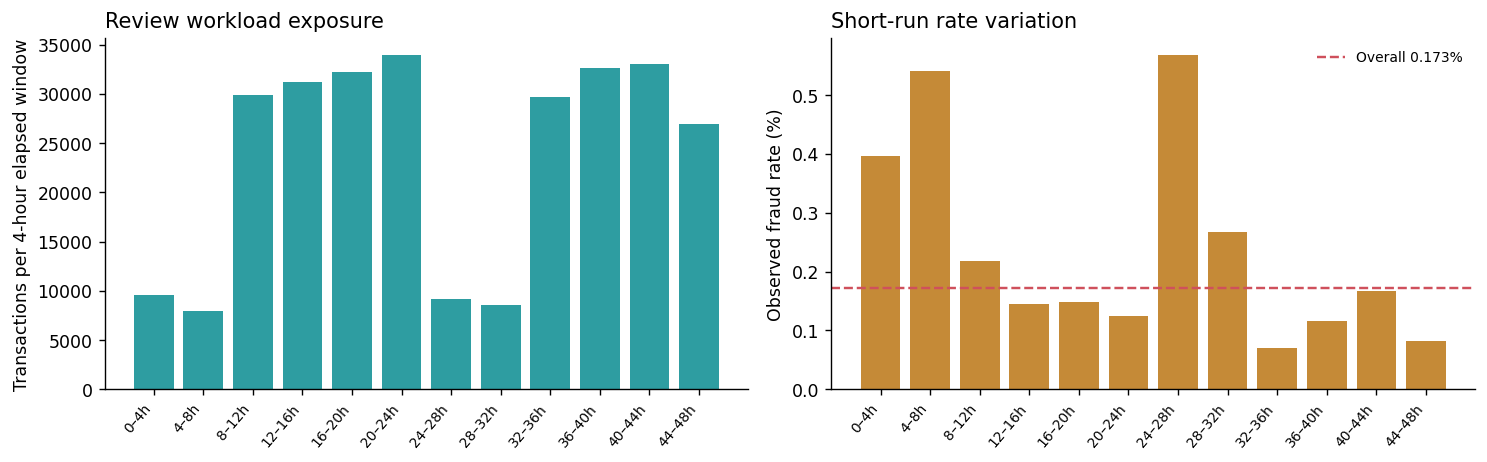

In [17]:
fig,axs=plt.subplots(1,2,figsize=(12,3.8))
xx=np.arange(len(time))
axs[0].bar(xx,time.transactions,color=TEAL,alpha=.85)
axs[0].set_xticks(xx,time.window,rotation=50,ha='right',fontsize=8)
axs[0].set_ylabel('Transactions per 4-hour elapsed window');axs[0].set_title('Review workload exposure',loc='left')
axs[1].bar(xx,time.fraud_rate_pct,color=GOLD)
axs[1].axhline(k.fraud_rate_pct,color=RED,ls='--',lw=1.4,label=f'Overall {k.fraud_rate_pct:.3f}%')
axs[1].set_xticks(xx,time.window,rotation=50,ha='right',fontsize=8)
axs[1].set_ylabel('Observed fraud rate (%)');axs[1].set_title('Short-run rate variation',loc='left')
axs[1].legend(frameon=False,fontsize=8)
fig.tight_layout();plt.show()

**Boundary.** A high observed rate in a short interval does not imply a predictable schedule or a high absolute fraudulent amount. Analyst scheduling requires longer time horizons, operational shift data and prospective validation. We use this view only to document historical volume-versus-rate heterogeneity.

## C · Retrospective review rules and hypothetical economics
### 11. Five descriptive segment-screen scenarios

The business module evaluates five rules by selecting transactions using their **observed amount segments**, and then *looking up true labels in the same original dataset*. These are **retrospective oracle summaries of segment coverage**, not deployed detection decisions or out-of-sample estimates. They show the cost of blanket review—not how a real reviewer would identify fraud.

In [18]:
ORDER=['review_all','review_zero_amount','review_lowest_amount_band','review_highest_amount_band','review_lowest_or_highest_band']
LABELS={'review_all':'Review all','review_zero_amount':'Zero amount',
        'review_lowest_amount_band':'Lowest decile','review_highest_amount_band':'Highest decile',
        'review_lowest_or_highest_band':'Lowest + highest'}
p=policy.set_index('policy').loc[ORDER].reset_index().copy()
p['Rule']=p.policy.map(LABELS)
assert (p.flagged_for_review==p.labeled_fraud_in_flagged+p.legitimate_in_flagged).all()
assert np.allclose(100*p.labeled_fraud_in_flagged/F,p.case_coverage_pct,atol=.002)
assert np.allclose(100*p.flagged_fraud_value/FV,p.value_coverage_pct,atol=.002)
show(p,['Rule','flagged_for_review','legitimate_in_flagged','labeled_fraud_in_flagged',
        'observed_review_yield_pct','case_coverage_pct','value_coverage_pct'],
     {'flagged_for_review':'{:,.0f}','legitimate_in_flagged':'{:,.0f}',
      'labeled_fraud_in_flagged':'{:,.0f}', 'observed_review_yield_pct':'{:.3f}',
      'case_coverage_pct':'{:.2f}', 'value_coverage_pct':'{:.2f}'})

,Rule,flagged_for_review,legitimate_in_flagged,labeled_fraud_in_flagged,observed_review_yield_pct,case_coverage_pct,value_coverage_pct
0,Review all,"284,807","284,315",492,0.173,100.00,100.00
1,Zero amount,"1,825","1,798",27,1.479,5.49,0.00
2,Lowest decile,"30,492","30,311",181,0.594,36.79,0.23
3,Highest decile,"28,458","28,373",85,0.299,17.28,78.11
4,Lowest + highest,"58,950","58,684",266,0.451,54.07,78.34


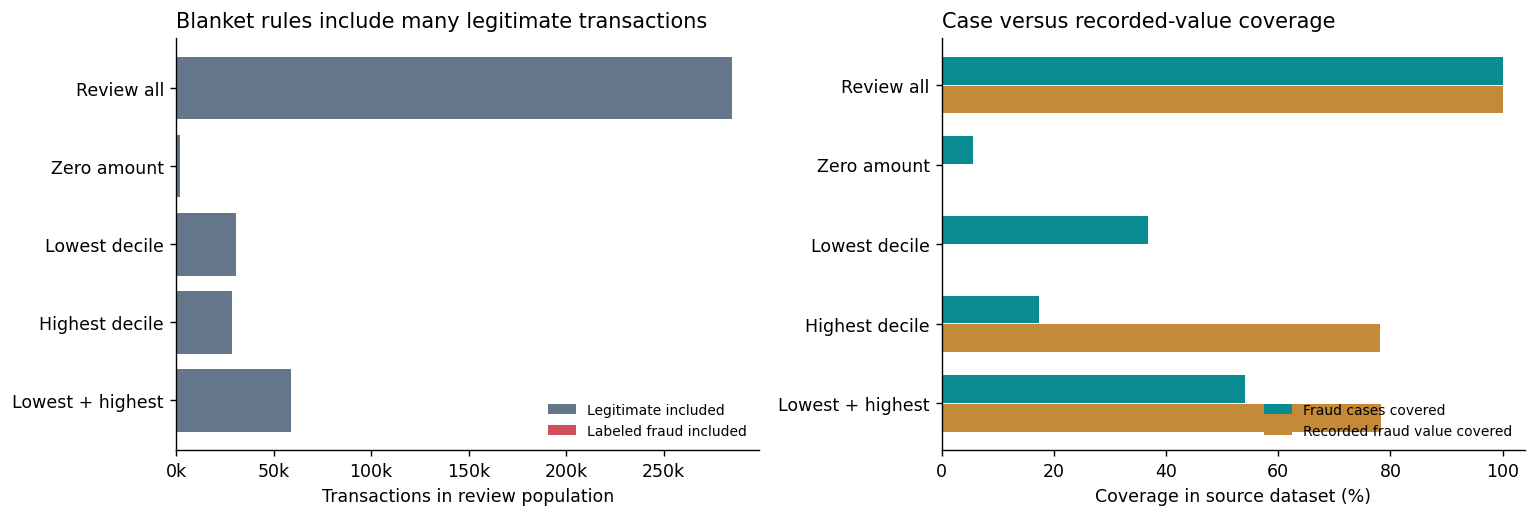

In [19]:
fig,axs=plt.subplots(1,2,figsize=(12.4,4.25))
y=np.arange(len(p))
axs[0].barh(y,p.legitimate_in_flagged,color=GREY,label='Legitimate included')
axs[0].barh(y,p.labeled_fraud_in_flagged,left=p.legitimate_in_flagged,color=RED,label='Labeled fraud included')
axs[0].set_yticks(y,p.Rule);axs[0].invert_yaxis();axs[0].set_xlabel('Transactions in review population')
axs[0].xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v/1000:.0f}k'))
axs[0].set_title('Blanket rules include many legitimate transactions',loc='left')
axs[0].legend(frameon=False,fontsize=8,loc='lower right')
axs[1].barh(y-.18,p.case_coverage_pct,height=.35,color=TEAL,label='Fraud cases covered')
axs[1].barh(y+.18,p.value_coverage_pct,height=.35,color=GOLD,label='Recorded fraud value covered')
axs[1].set_yticks(y,p.Rule);axs[1].invert_yaxis();axs[1].set_xlim(0,104)
axs[1].set_xlabel('Coverage in source dataset (%)')
axs[1].set_title('Case versus recorded-value coverage',loc='left')
axs[1].legend(frameon=False,fontsize=8,loc='lower right')
fig.tight_layout();plt.show()

**Operational interpretation.** Reviewing the highest decile covers **85 of 492 fraud cases** and **78.11% of recorded fraudulent value**, but entails **28,458 reviews**, including **28,373 legitimate transactions**. The lowest-decile rule covers many more fraud labels but almost no recorded fraudulent value. None of these results establishes customer harm, real investigation success or financial gain; the source labels are known *after the fact*.

### 12. Review efficiency: capacity, observed yield and false-alert burden

A segment's case coverage is only half the workload story. For each rule, compute **labeled frauds per 1,000 reviews** and **legitimate reviews per labeled fraud** from the original rule summary, then compare with the baseline fraud prevalence. These are descriptive, in-sample efficiencies, not model precision measured prospectively.

In [20]:
p['Frauds per 1,000 reviews']=1000*p.labeled_fraud_in_flagged/p.flagged_for_review
p['Legitimate reviews per fraud']=p.legitimate_in_flagged/p.labeled_fraud_in_flagged.replace(0,np.nan)
show(p,['Rule','flagged_for_review','reviews_per_1000_transactions','Frauds per 1,000 reviews',
        'Legitimate reviews per fraud','case_coverage_pct','value_coverage_pct'],
     {'flagged_for_review':'{:,.0f}','reviews_per_1000_transactions':'{:.2f}',
      'Frauds per 1,000 reviews':'{:.2f}','Legitimate reviews per fraud':'{:,.1f}',
      'case_coverage_pct':'{:.2f}','value_coverage_pct':'{:.2f}'})

,Rule,flagged_for_review,reviews_per_1000_transactions,"Frauds per 1,000 reviews",Legitimate reviews per fraud,case_coverage_pct,value_coverage_pct
0,Review all,"284,807",1000.00,1.73,577.9,100.00,100.00
1,Zero amount,"1,825",6.41,14.79,66.6,5.49,0.00
2,Lowest decile,"30,492",107.06,5.94,167.5,36.79,0.23
3,Highest decile,"28,458",99.92,2.99,333.8,17.28,78.11
4,Lowest + highest,"58,950",206.98,4.51,220.6,54.07,78.34


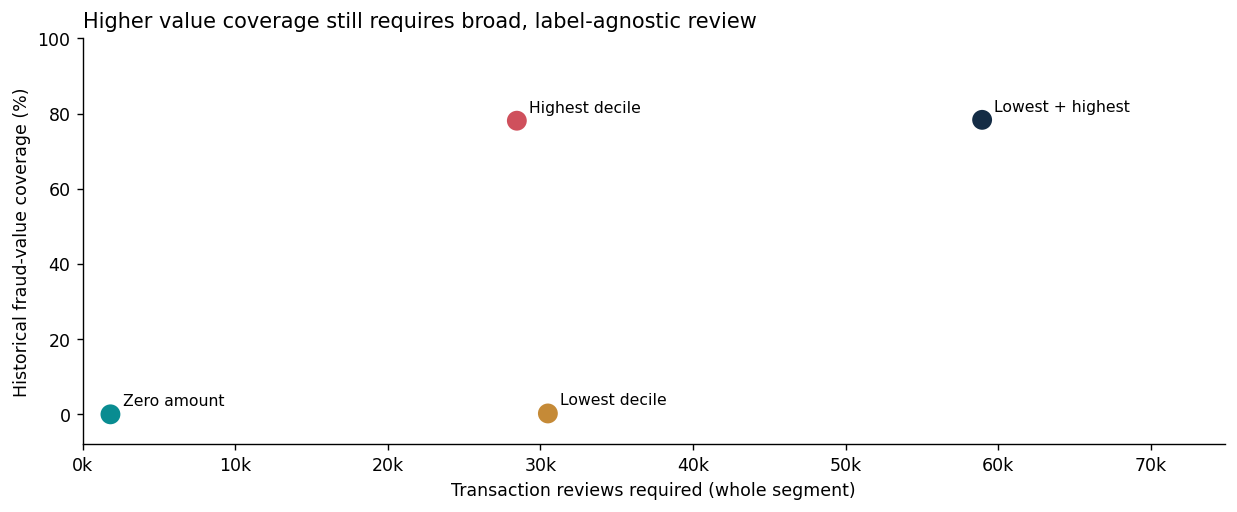

In [21]:
fig,ax=plt.subplots(figsize=(10,4.2))
sub=p[p.policy.ne('review_all')]
ax.scatter(sub.flagged_for_review,sub.value_coverage_pct,s=160,c=[TEAL,GOLD,RED,NAVY],edgecolors='white',linewidths=1.2)
for _,row in sub.iterrows():
 ax.annotate(row.Rule,(row.flagged_for_review,row.value_coverage_pct),xytext=(7,5),textcoords='offset points',fontsize=9)
ax.set_xlabel('Transaction reviews required (whole segment)')
ax.set_ylabel('Historical fraud-value coverage (%)')
ax.set_ylim(-8,100);ax.set_xlim(0,sub.flagged_for_review.max()*1.27)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v/1000:.0f}k'))
ax.set_title('Higher value coverage still requires broad, label-agnostic review',loc='left')
chart_finish(fig)

**Bridge to modeling.** These segment rules do not rank individual transactions within the selected population; all selected records become review candidates. A separate score-based system can prioritize *within* a constrained queue, but its actual benefit must be judged on a locked holdout and the same review-budget denominator (Notebooks 03–04). We do **not** compare these in-sample rules directly against ML holdout performance.

### 13. Assumption sensitivity: 45 hypothetical accounting scenarios

The business module crosses **five review populations × three assumed review costs (1, 5, 10) × three assumed effectiveness levels (25%, 50%, 100%)**. The saved grid assumes **zero additional friction cost per legitimate review**. Neither effectiveness nor review costs were measured in this dataset.

The simple accounting identity is:

\[\text{Gross hypothetical value}=\text{recorded fraud value flagged}\times\text{assumed effectiveness}\]

\[\text{Hypothetical net}=\text{gross hypothetical value}-\text{review cost}-\text{additional assumed friction cost}\]

**Warning:** "value flagged" is not verified preventable loss; even a positive hypothetical value would not establish realizable profit.

In [22]:
scenario=reports['assumption_sensitivity'].copy()
assert len(scenario)==len(p)*3*3
assert set(scenario.policy)==set(p.policy)
assert sorted(scenario.assumed_cost_per_review.unique().tolist())==[1.,5.,10.]
assert np.allclose(sorted(scenario.assumed_fraud_intervention_effectiveness.unique()),[.25,.5,1.])
assert np.allclose(scenario.assumed_friction_cost_per_legitimate_review,0.)
assert np.allclose(scenario.gross_hypothetical_value_prevented-scenario.total_review_cost-
                   scenario.total_false_positive_friction_cost,scenario.hypothetical_incremental_net_value,atol=.001)
assert np.allclose(scenario.total_review_cost,
                   scenario.flagged_for_review*scenario.assumed_cost_per_review,atol=.001)
for policy_name, row in p.set_index('policy').iterrows():
 g=scenario[scenario.policy.eq(policy_name)]
 assert np.allclose(g.gross_hypothetical_value_prevented,g.assumed_fraud_intervention_effectiveness*row.flagged_fraud_value,atol=.001)
print('PASS — all 45 hypothetical scenarios reconcile to their source rules and accounting identities')
print('Cost assumptions:',sorted(scenario.assumed_cost_per_review.unique()),'amount units per review')
print('Effectiveness assumptions:',sorted(scenario.assumed_fraud_intervention_effectiveness.unique()))
print('Additional false-alert friction cost: zero in the source sensitivity grid')

PASS — all 45 hypothetical scenarios reconcile to their source rules and accounting identities
Cost assumptions: [np.float64(1.0), np.float64(5.0), np.float64(10.0)] amount units per review
Effectiveness assumptions: [np.float64(0.25), np.float64(0.5), np.float64(1.0)]
Additional false-alert friction cost: zero in the source sensitivity grid


In [23]:
scenario['Rule']=scenario.policy.map(LABELS)
base=scenario.loc[scenario.assumed_cost_per_review.eq(5.) & scenario.assumed_fraud_intervention_effectiveness.eq(.5)].copy()
show(base,['Rule','flagged_for_review','gross_hypothetical_value_prevented','total_review_cost',
           'total_false_positive_friction_cost','hypothetical_incremental_net_value'],
     {'flagged_for_review':'{:,.0f}', 'gross_hypothetical_value_prevented':'{:,.2f}',
      'total_review_cost':'{:,.2f}', 'total_false_positive_friction_cost':'{:,.2f}',
      'hypothetical_incremental_net_value':'{:,.2f}'},
     'Illustrative middle scenario: review cost = 5 units; effectiveness = 50%; friction cost = 0')

*Illustrative middle scenario: review cost = 5 units; effectiveness = 50%; friction cost = 0*

,Rule,flagged_for_review,gross_hypothetical_value_prevented,total_review_cost,total_false_positive_friction_cost,hypothetical_incremental_net_value
4,Review all,"284,807","30,063.99","1,424,035.00",0.00,"-1,393,971.01"
13,Zero amount,"1,825",0.00,"9,125.00",0.00,"-9,125.00"
22,Lowest decile,"30,492",69.78,"152,460.00",0.00,"-152,390.22"
31,Highest decile,"28,458","23,482.94","142,290.00",0.00,"-118,807.05"
40,Lowest + highest,"58,950","23,552.72","294,750.00",0.00,"-271,197.28"


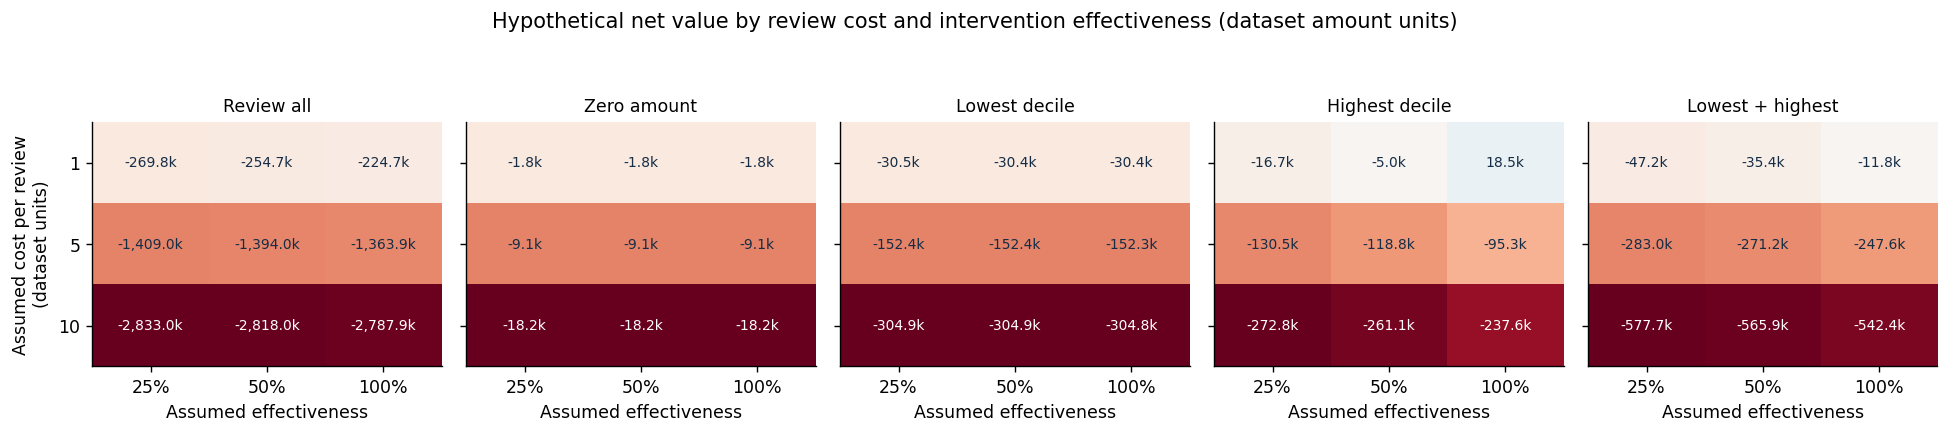

In [24]:
costs=sorted(scenario.assumed_cost_per_review.unique())
effects=sorted(scenario.assumed_fraud_intervention_effectiveness.unique())
fig,axs=plt.subplots(1,5,figsize=(15.7,3.2),sharey=True)
for ax,pr in zip(axs,ORDER):
 d=scenario.loc[scenario.policy.eq(pr)]
 mat=d.pivot(index='assumed_cost_per_review',columns='assumed_fraud_intervention_effectiveness',values='hypothetical_incremental_net_value').loc[costs,effects]
 values=mat.to_numpy()/1000
 lim=max(np.max(np.abs(values)),1.)
 im=ax.imshow(values,cmap='RdBu',vmin=-lim,vmax=lim,aspect='auto')
 ax.set_xticks(range(3),['25%','50%','100%']);ax.set_yticks(range(3),['1','5','10'])
 ax.set_title(LABELS[pr],fontsize=10)
 ax.set_xlabel('Assumed effectiveness')
 for i in range(3):
  for j in range(3): ax.text(j,i,f'{values[i,j]:,.1f}k',ha='center',va='center',color='white' if abs(values[i,j])>lim*.55 else NAVY,fontsize=8)
axs[0].set_ylabel('Assumed cost per review\n(dataset units)')
fig.suptitle('Hypothetical net value by review cost and intervention effectiveness (dataset amount units)',fontsize=12,y=1.07)
fig.tight_layout();plt.show()

**Sensitivity interpretation.** Hypothetical net values can become strongly negative because reviewing tens of thousands of legitimate transactions incurs costs while the recorded fraud amount is limited. Under these *unverified assumptions*, zero-amount reviews have zero gross amount-based benefit even though some records carry a fraud label. This is a property of the **accounting definition**, not proof that such records have no operational value or nonfinancial harm. The saved grid assumes no additional friction cost; actual customer impact could be material. Do not select a real-world policy using these oracle scenarios.

### 14. Illustrative break-even requirements (derived, not independently observed)

For each fixed review population, the break-even effectiveness under a specified review cost is:

\[ e_{\mathrm{break-even}}=\frac{\text{number of reviews}\times\text{cost per review}+\text{friction cost}}{\text{recorded fraud value flagged}} \]

This ratio is **not a probability estimate**. Values above 100% mean even an assumed 100% intervention effectiveness cannot cover the modeled cost. For a segment with zero recorded fraud amount, this model has no finite break-even effectiveness at positive review cost.

In [25]:
cost=5.
break_even=p[['Rule','flagged_for_review','flagged_fraud_value','legitimate_in_flagged']].copy()
break_even['Illustrative review cost']=cost*break_even.flagged_for_review
break_even['Break-even effectiveness (%)']=np.where(break_even.flagged_fraud_value.gt(0),
  100*break_even['Illustrative review cost']/break_even.flagged_fraud_value,np.nan)
break_even['Feasible at ≤100%?']=break_even['Break-even effectiveness (%)'].le(100).fillna(False)
show(break_even,['Rule','flagged_for_review','flagged_fraud_value','Illustrative review cost',
                 'Break-even effectiveness (%)','Feasible at ≤100%?'],
     {'flagged_for_review':'{:,.0f}','flagged_fraud_value':'{:,.2f}',
      'Illustrative review cost':'{:,.2f}','Break-even effectiveness (%)':'{:,.1f}'})
print('Undefined values mean zero recorded fraudulent value in the reviewed segment.')

,Rule,flagged_for_review,flagged_fraud_value,Illustrative review cost,Break-even effectiveness (%),Feasible at ≤100%?
0,Review all,"284,807","60,127.97","1,424,035.00","2,368.3",False
1,Zero amount,"1,825",0.00,"9,125.00",—,False
2,Lowest decile,"30,492",139.56,"152,460.00","109,243.3",False
3,Highest decile,"28,458","46,965.89","142,290.00",303.0,False
4,Lowest + highest,"58,950","47,105.45","294,750.00",625.7,False


Undefined values mean zero recorded fraudulent value in the reviewed segment.


## 15. Evidence-to-action register and methodological boundaries

The register below intentionally separates **what was observed**, **what it could imply**, **why it is limited**, and **what analysis must follow**. Its suggestions are research priorities, not prescribed fraud blocking rules.

In [26]:
register=pd.DataFrame([
 ('Amount tests Holm-significant','Distribution differences warrant study','Large N; tied KS values; small Cramér’s V','Test out-of-sample predictive usefulness'),
 ('Zero-amount RR ~9','Contextual risk review may be informative','Rare absolute event; reason for zero amount unknown','Investigate contextual data and false-alert burden'),
 ('Highest decile dominates recorded fraud value','Track case and value recall separately','Amount ≠ verified loss; 28k+ reviews for blanket rule','Use capacity-constrained holdout ranking'),
 ('Selected PCA features differ by class','Anonymized signals support predictive experiments','Post-EDA selection; no feature semantics','Use leakage-free pipelines and temporal validation'),
 ('Duplicate removal changes 19 fraud labels','Preserve preprocessing provenance','Cannot identify whether identical rows are mistakes','Compare documented original/dedup populations'),
 ('Oracle segment rules review many legitimate cases','Capacity and customer burden matter','In-sample coverage, not deployed performance','Evaluate model-based review queues'),
 ('45 financial scenarios depend on assumptions','Stress-test operational economics','Unknown costs, effectiveness, currency and loss','Collect real outcome/cost data before deployment')],
 columns=['Observed evidence','Potential implication','Limitation','Next analytical action'])
show(register)

,Observed evidence,Potential implication,Limitation,Next analytical action
0,Amount tests Holm-significant,Distribution differences warrant study,Large N; tied KS values; small Cramér’s V,Test out-of-sample predictive usefulness
1,Zero-amount RR ~9,Contextual risk review may be informative,Rare absolute event; reason for zero amount unknown,Investigate contextual data and false-alert burden
2,Highest decile dominates recorded fraud value,Track case and value recall separately,Amount ≠ verified loss; 28k+ reviews for blanket rule,Use capacity-constrained holdout ranking
3,Selected PCA features differ by class,Anonymized signals support predictive experiments,Post-EDA selection; no feature semantics,Use leakage-free pipelines and temporal validation
4,Duplicate removal changes 19 fraud labels,Preserve preprocessing provenance,Cannot identify whether identical rows are mistakes,Compare documented original/dedup populations
5,Oracle segment rules review many legitimate cases,Capacity and customer burden matter,"In-sample coverage, not deployed performance",Evaluate model-based review queues
6,45 financial scenarios depend on assumptions,Stress-test operational economics,"Unknown costs, effectiveness, currency and loss",Collect real outcome/cost data before deployment


### Final answers and handoff

**RQ1 — Distributional evidence.** Amount differences and the selected anonymized features show exploratory statistical evidence; test significance and operational usefulness remain distinct.  
**RQ2 — Segment risk.** Zero-amount records have elevated observed relative fraud risk with uncertainty, but a low absolute rate and no recorded transaction value.  
**RQ3 — PCA.** Some selected anonymized components have substantial rank-based class separation, without interpretable causal business meaning.  
**RQ4 — Robustness.** A conditional fraud-row bootstrap places an interval around highest-decile value concentration; deduplication changes the population, fraud count and several observed measures.  
**RQ5 — Operational feasibility.** Broad amount-based rules can cover substantial recorded fraud value while requiring tens of thousands of mostly legitimate reviews; economic results depend on explicitly hypothetical inputs.

**What this notebook does *not* establish:** a deployable review policy, probability calibration, cost-effective production performance, prevented bank loss, fraud causality, recurring time-of-day risk, or any proven financial savings.

**Next — `03_ml_experiments_evaluation.ipynb`:** Explain training-only model selection, stratified versus chronological holdout designs, average precision, false positives, false negatives, and fraud-value recall. **Then — Notebook 04:** compare training-selected queue-ranking rules at predeclared review budgets without holdout-based tuning.

In [27]:
print('FINAL AUDIT')
print(f'Original population: {N:,} transactions | {F:,} fraud labels | fraud value {FV:,.2f} unverified units')
print(f'Tests: {len(tests)} | report bootstrap replicates: {int(unc.bootstrap_resamples):,}')
print(f'Segment review rules: {len(p)} | cost/effectiveness scenarios: {len(scenario)}')
print('PASS — Notebook 02 conclusions rest on reconciled saved reports, not reproduced statistical tests.')

FINAL AUDIT
Original population: 284,807 transactions | 492 fraud labels | fraud value 60,127.97 unverified units
Tests: 9 | report bootstrap replicates: 2,000
Segment review rules: 5 | cost/effectiveness scenarios: 45
PASS — Notebook 02 conclusions rest on reconciled saved reports, not reproduced statistical tests.
